# Лабораторная работа 2

**Сверточные нейронные сети и обработка изображений**

**Тема.** Сверточные нейронные сети. Классификация изображений.
DeepDream. Передача стиля.

**Задание.** Выбрать предметную область и датасет изображений для задачи классификации. С использованием PyTorch/torchvision разработать CNN для классификации изображений.

In [1]:
import criterion
import torch_directml


device = torch_directml.device()
print(f"Используемое устройство: {device}")

Используемое устройство: privateuseone:0


Предобработка изображений

In [3]:
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Загрузка датасета

In [4]:
import torch
import torchvision

train_dataset = torchvision.datasets.ImageFolder(root='./data/train', transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)

## Анализ датасета

In [5]:
print(f"Классы, обнаруженные в датасете: {train_dataset.classes}")
print(f"Общее количество картинок в тренировочной выборке: {len(train_dataset)}")

# и проверка на одном батче
images, labels = next(iter(train_loader))
print(f"Размер тензора батча картинок: {images.shape}")
print(f"Размер тензора меток: {labels.shape}")

Классы, обнаруженные в датасете: ['Ac', 'As', 'Cb', 'Cc', 'Ci', 'Cs', 'Ct', 'Cu', 'Ns', 'Sc', 'St']
Общее количество картинок в тренировочной выборке: 2323
Размер тензора батча картинок: torch.Size([32, 3, 128, 128])
Размер тензора меток: torch.Size([32])


Анализ баланса классов

Распределение классов по количеству изображений:
  Ac: 201 изображений
  As: 168 изображений
  Cb: 222 изображений
  Cc: 248 изображений
  Ci: 119 изображений
  Cs: 267 изображений
  Ct: 180 изображений
  Cu: 162 изображений
  Ns: 254 изображений
  Sc: 320 изображений
  St: 182 изображений


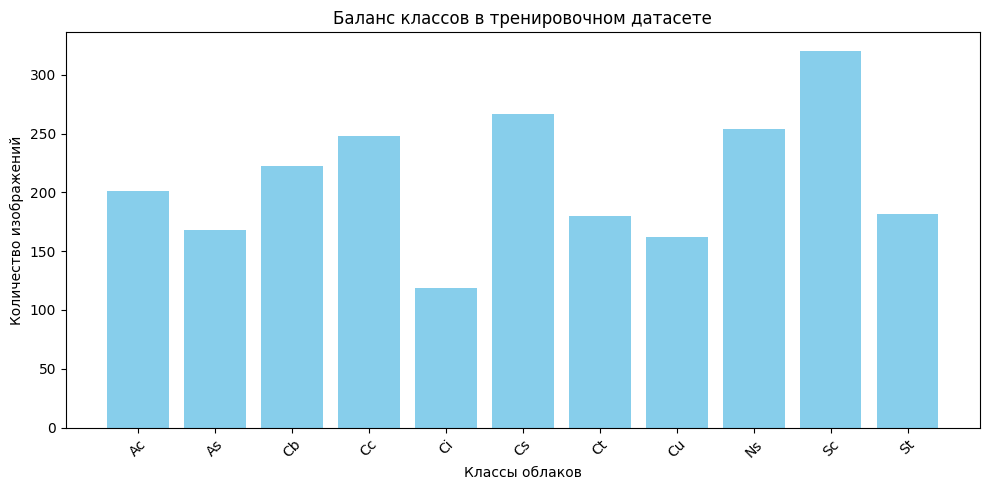

In [8]:
import matplotlib.pyplot as plt
from collections import Counter

targets = train_dataset.targets

class_counts = Counter(targets)
class_names = train_dataset.classes

print("Распределение классов по количеству изображений:")
for idx, count in class_counts.items():
    print(f"  {class_names[idx]}: {count} изображений")

plt.figure(figsize=(10, 5))
plt.bar([class_names[i] for i in class_counts.keys()], list(class_counts.values()), color='skyblue')
plt.xlabel('Классы облаков')
plt.ylabel('Количество изображений')
plt.title('Баланс классов в тренировочном датасете')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Дисбаланс имеется, но не самый большой

Визуализация классов для понимания

In [17]:
cloud_descriptions = {
    'Ac': 'Altocumulus (Высококучевые)',
    'As': 'Altostratus (Высокослоистые)',
    'Cb': 'Cumulonimbus (Кучево-дождевые)',
    'Cc': 'Cirrocumulus (Перисто-кучевые)',
    'Ci': 'Cirrus (Перистые)',
    'Cs': 'Cirrostratus (Перисто-слоистые)',
    'Ct': 'Contrail / Clear sky (Инверсионные следы / Чистое небо)',
    'Cu': 'Cumulus (Кучевые)',
    'Ns': 'Nimbostratus (Слоисто-дождевые)',
    'Sc': 'Stratocumulus (Слоисто-кучевые)',
    'St': 'Stratus (Слоистые)'
}

In [21]:
from collections import defaultdict
import numpy as np

def show_random_samples(dataset):
    class_to_indices = defaultdict(list)
    for idx, (_, label) in enumerate(dataset.samples):
        class_to_indices[label].append(idx)

    num_classes = len(dataset.classes)

    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    axes = axes.flatten()

    for label_idx in range(num_classes):
        random_idx = np.random.choice(class_to_indices[label_idx])
        img, _ = dataset[random_idx]

        img_permuted = img.permute(1, 2, 0).numpy()
        img_permuted = np.clip(img_permuted, 0, 1)

        class_code = dataset.classes[label_idx]
        full_name = cloud_descriptions.get(class_code, class_code)

        axes[label_idx].imshow(img_permuted)
        axes[label_idx].set_title(f"{class_code}: {full_name}", fontsize=10)
        axes[label_idx].axis('off')

    if num_classes < len(axes):
        axes[-1].axis('off')

    plt.tight_layout()
    plt.show()

In [19]:
# без нормлаизации
transform_for_viz = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

viz_dataset = torchvision.datasets.ImageFolder(root='./data/train', transform=transform_for_viz)

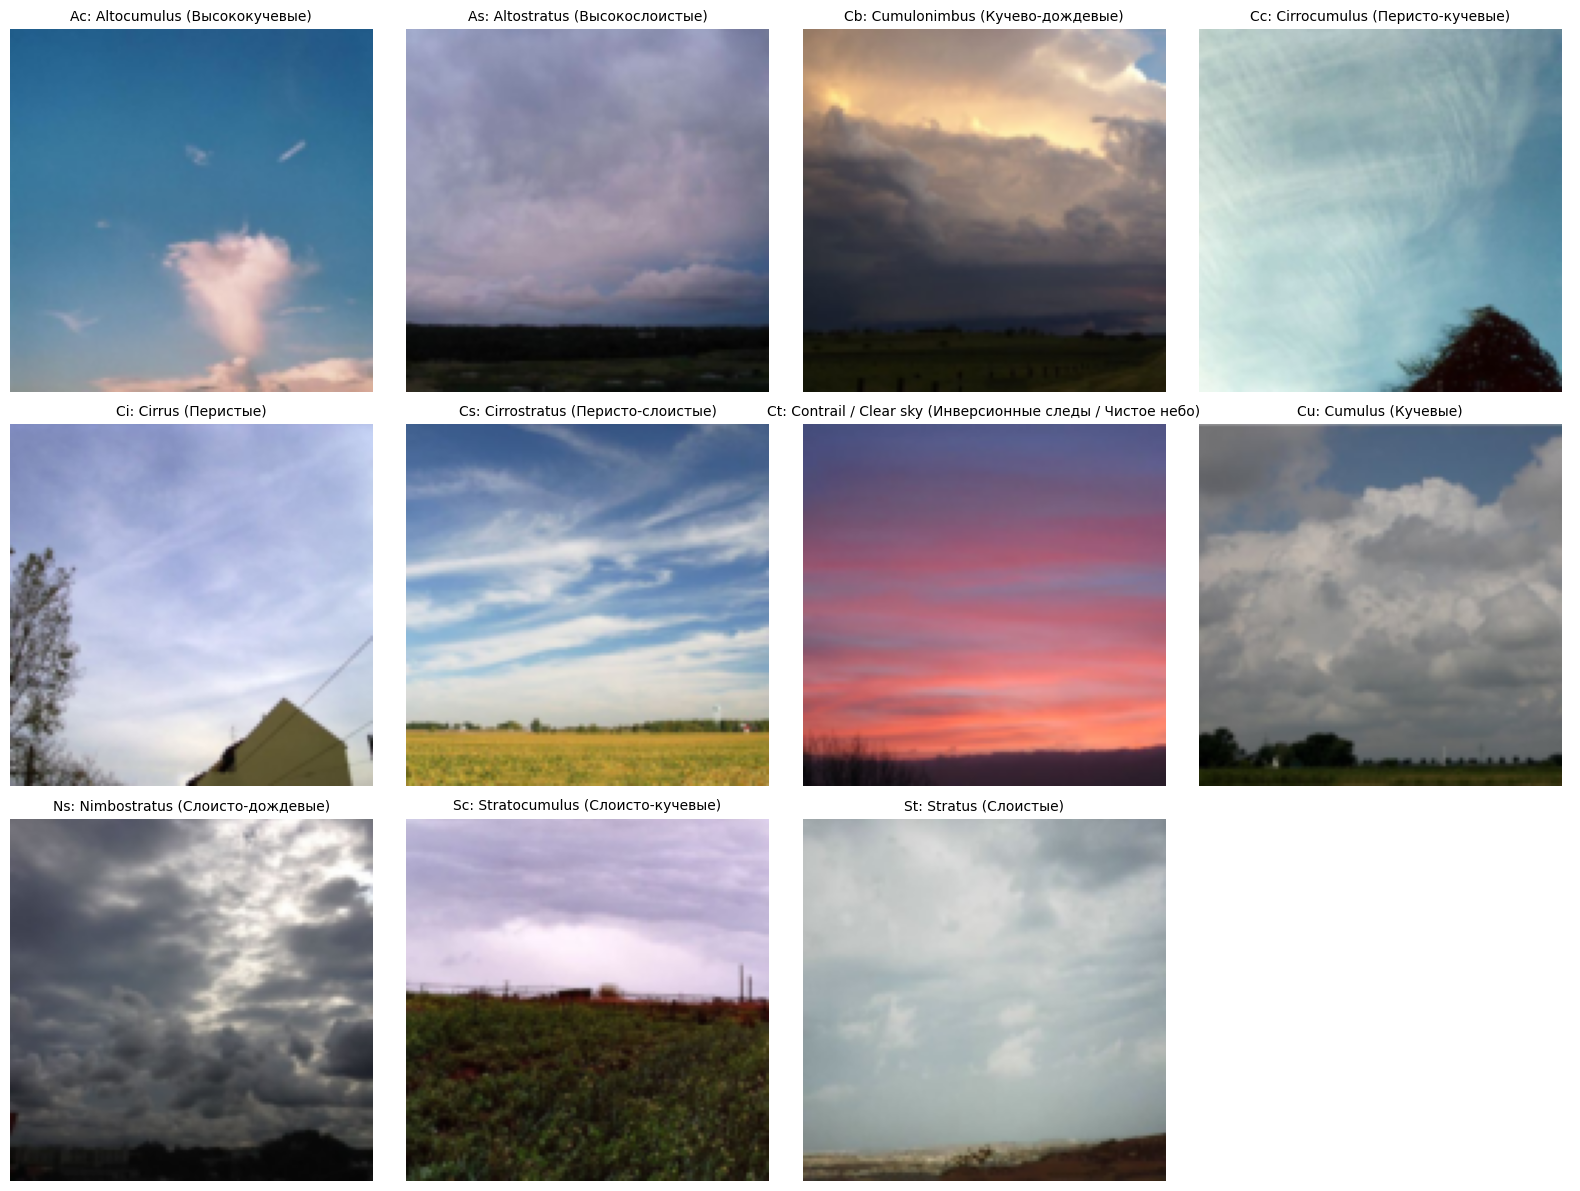

In [22]:
show_random_samples(viz_dataset)

In [16]:
print("Расшифровка классов датасета:")
for code in train_dataset.classes:
    print(f"  • {code}: {cloud_descriptions.get(code, 'Описание отсутствует')}")

Расшифровка классов датасета:
  • Ac: Altocumulus (Высококучевые)
  • As: Altostratus (Высокослоистые)
  • Cb: Cumulonimbus (Кучево-дождевые)
  • Cc: Cirrocumulus (Перисто-кучевые)
  • Ci: Cirrus (Перистые)
  • Cs: Cirrostratus (Перисто-слоистые)
  • Ct: Contrail / Clear sky (Инверсионные следы / Чистое небо)
  • Cu: Cumulus (Кучевые)
  • Ns: Nimbostratus (Слоисто-дождевые)
  • Sc: Stratocumulus (Слоисто-кучевые)
  • St: Stratus (Слоистые)


## Обучение CNN

In [35]:
param_grid_cnn = {
    'num_blocks': [2, 3],                    # Количество сверточных блоков
    'base_filters': [16, 32],                   # Количество фильтров
    'kernel_size': [3, 5],                      # Размер kernel
    'pool_type': ['max', 'avg'],                # pooling
    'use_bn': [True, False],                    # BatchNorm
    'use_dropout': [True, False],               # Dropout
    'augmented': [True, False],                 # Аугментация изображений
    'learning_rate': [0.001]
}

In [25]:
import torch.nn as nn
import torch.optim as optim
import itertools

class ConfigurableCNN(nn.Module):
    def __init__(self, num_classes=11, num_blocks=3, base_filters=32,
                 kernel_size=3, pool_type='max', use_bn=True,
                 use_dropout=True, dropout_rate=0.5):
        super(ConfigurableCNN, self).__init__()

        layers = []
        in_channels = 3
        current_size = 128

        for i in range(num_blocks):
            out_channels = base_filters * (2 ** i)
            padding = kernel_size // 2

            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding))
            if use_bn:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.append(nn.ReLU())

            # Динамический выбор типов Pooling
            if pool_type == 'max':
                layers.append(nn.MaxPool2d(2, 2))
            elif pool_type == 'avg':
                layers.append(nn.AvgPool2d(2, 2))

            in_channels = out_channels
            current_size = current_size // 2

        self.features = nn.Sequential(*layers)

        classifier_layers = [
            nn.Flatten(),
            nn.Linear(in_channels * current_size * current_size, 256),
            nn.ReLU()
        ]
        if use_dropout:
            classifier_layers.append(nn.Dropout(dropout_rate))
        classifier_layers.append(nn.Linear(256, num_classes))

        self.classifier = nn.Sequential(*classifier_layers)

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [26]:
def train_and_evaluate(model, train_loader, criterion, optimizer, epochs=2):
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        epoch_acc = correct / total
    return epoch_acc

In [32]:
import time
import pandas as pd

def grid_search_cnn(param_grid, epochs=2):
    transform_augmented = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    transform_clean = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    keys = param_grid.keys()
    values = param_grid.values()
    combinations = [dict(zip(keys, combination)) for combination in itertools.product(*values)]

    print(f"Всего конфигураций для исследования: {len(combinations)}\n")

    results_list = []
    best_accuracy = 0.0
    best_params = None

    for i, params in enumerate(combinations, 1):
        print(f"Конфигурация [{i}/{len(combinations)}]")
        print(params)

        current_transform = transform_augmented if params['augmented'] else transform_clean

        model = ConfigurableCNN(
            num_blocks=params['num_blocks'],
            base_filters=params['base_filters'],
            kernel_size=params['kernel_size'],
            pool_type=params['pool_type'],
            use_bn=params['use_bn'],
            use_dropout=params['use_dropout']
        ).to(device)

        optimizer = optim.Adam(model.parameters(), lr=params['learning_rate'])

        start_time = time.time()
        acc = train_and_evaluate(model, train_loader, criterion, optimizer, epochs=epochs)
        elapsed_time = time.time() - start_time

        acc_percent = round(acc * 100, 2)
        print(f"Результат (Accuracy): {acc_percent}% | Время обучения: {elapsed_time:.2f} сек.\n")

        row_data = params.copy()
        row_data['accuracy'] = acc_percent
        row_data['time_sec'] = round(elapsed_time, 2)
        results_list.append(row_data)

        if acc > best_accuracy:
            best_accuracy = acc
            best_params = params

    df_results = pd.DataFrame(results_list)

    print("="*40)
    print(f"Лучшая точность: {best_accuracy*100:.2f}%")
    print(f"Лучшие параметры: {best_params}")
    print("="*40)

    return df_results

In [36]:
grid_search_cnn(param_grid_cnn, epochs=3)

Всего конфигураций для исследования: 128

Конфигурация [1/128]
{'num_blocks': 2, 'base_filters': 16, 'kernel_size': 3, 'pool_type': 'max', 'use_bn': True, 'use_dropout': True, 'augmented': True, 'learning_rate': 0.001}
Результат (Accuracy): 17.35% | Время обучения: 44.23 сек.

Конфигурация [2/128]
{'num_blocks': 2, 'base_filters': 16, 'kernel_size': 3, 'pool_type': 'max', 'use_bn': True, 'use_dropout': True, 'augmented': False, 'learning_rate': 0.001}
Результат (Accuracy): 18.25% | Время обучения: 42.38 сек.

Конфигурация [3/128]
{'num_blocks': 2, 'base_filters': 16, 'kernel_size': 3, 'pool_type': 'max', 'use_bn': True, 'use_dropout': False, 'augmented': True, 'learning_rate': 0.001}
Результат (Accuracy): 32.5% | Время обучения: 44.15 сек.

Конфигурация [4/128]
{'num_blocks': 2, 'base_filters': 16, 'kernel_size': 3, 'pool_type': 'max', 'use_bn': True, 'use_dropout': False, 'augmented': False, 'learning_rate': 0.001}
Результат (Accuracy): 30.35% | Время обучения: 44.92 сек.

Конфигураци

,num_blocks,base_filters,kernel_size,pool_type,use_bn,use_dropout,augmented,learning_rate,accuracy,time_sec
0,2,16,3,max,True,True,True,0.001,17.35,44.23
1,2,16,3,max,True,True,False,0.001,18.25,42.38
2,2,16,3,max,True,False,True,0.001,32.50,44.15
3,2,16,3,max,True,False,False,0.001,30.35,44.92
4,2,16,3,max,False,True,True,0.001,34.91,40.24
...,...,...,...,...,...,...,...,...,...,...
123,3,32,5,avg,True,False,False,0.001,31.55,59.96
124,3,32,5,avg,False,True,True,0.001,27.85,52.72
125,3,32,5,avg,False,True,False,0.001,27.64,52.45
126,3,32,5,avg,False,False,True,0.001,31.51,52.35


Лучшая конфигурация

In [39]:
best_params = {
    'num_blocks': 2,
    'base_filters': 16,
    'kernel_size': 3,
    'pool_type': 'max',
    'use_bn': False,
    'use_dropout': False,
    'augmented': True,
    'learning_rate': 0.001
}

In [57]:
transform_train = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [60]:
transform_clean = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [61]:
train_full_dataset = torchvision.datasets.ImageFolder(root='./data/train', transform=transform_train)
test_full_dataset = torchvision.datasets.ImageFolder(root='./data/train', transform=transform_clean)

In [62]:
torch.manual_seed(42)
test_size = int(0.2 * len(train_full_dataset))
train_size = len(train_full_dataset) - test_size

indices = torch.randperm(len(train_full_dataset)).tolist()
train_indices = indices[:train_size]
test_indices = indices[train_size:]

train_subset = torch.utils.data.Subset(train_full_dataset, train_indices)
test_subset = torch.utils.data.Subset(test_full_dataset, test_indices)

train_loader = torch.utils.data.DataLoader(train_subset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_subset, batch_size=32, shuffle=False)

print(f"Размер обучающей выборки: {len(train_subset)} картинок")
print(f"Размер тестовой выборки: {len(test_subset)} картинок\n")

Размер обучающей выборки: 1859 картинок
Размер тестовой выборки: 464 картинок



In [66]:
best_model = ConfigurableCNN(
    num_classes=11,
    num_blocks=best_params['num_blocks'],
    base_filters=best_params['base_filters'],
    kernel_size=best_params['kernel_size'],
    pool_type=best_params['pool_type'],
    use_bn=best_params['use_bn'],
    use_dropout=best_params['use_dropout']
).to(device)

In [67]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(best_model.parameters(), lr=best_params['learning_rate'])

In [68]:
epochs = 50
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [69]:
import time
import numpy as np
from sklearn.metrics import precision_recall_fscore_support

history_loss = []
history_acc = []
history_precision = []
history_recall = []
history_f1 = []

print(f"Запуск обучения лучшей модели, ({epochs} эпох)...\n")
total_start_time = time.time()

for epoch in range(epochs):
    epoch_start_time = time.time()
    best_model.train()
    running_loss = 0.0

    all_preds = []
    all_labels = []

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = best_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    scheduler.step()

    epoch_time = time.time() - epoch_start_time
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average='macro', zero_division=0
    )

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = (sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)) * 100

    history_loss.append(epoch_loss)
    history_acc.append(epoch_acc)
    history_precision.append(precision * 100)
    history_recall.append(recall * 100)
    history_f1.append(f1 * 100)

    print(f"Эпоха {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.2f}% | Время: {epoch_time:.2f}с")

total_time = time.time() - total_start_time
print(f"\nОбучение завершено за {total_time:.2f} сек. (~{total_time/60:.2f} мин.)")

Запуск обучения лучшей модели, (50 эпох)...

Эпоха 1/50 | Loss: 2.3359 | Acc: 22.05% | Время: 11.25с
Эпоха 2/50 | Loss: 2.0354 | Acc: 27.97% | Время: 10.91с
Эпоха 3/50 | Loss: 1.9601 | Acc: 31.52% | Время: 11.18с
Эпоха 4/50 | Loss: 1.9030 | Acc: 32.87% | Время: 10.84с
Эпоха 5/50 | Loss: 1.8436 | Acc: 35.83% | Время: 10.77с
Эпоха 6/50 | Loss: 1.7803 | Acc: 38.30% | Время: 10.68с
Эпоха 7/50 | Loss: 1.6912 | Acc: 40.77% | Время: 10.81с
Эпоха 8/50 | Loss: 1.6288 | Acc: 42.66% | Время: 10.60с
Эпоха 9/50 | Loss: 1.5459 | Acc: 45.35% | Время: 11.09с
Эпоха 10/50 | Loss: 1.4767 | Acc: 49.06% | Время: 10.59с
Эпоха 11/50 | Loss: 1.4250 | Acc: 51.21% | Время: 10.87с
Эпоха 12/50 | Loss: 1.3651 | Acc: 52.29% | Время: 11.11с
Эпоха 13/50 | Loss: 1.2741 | Acc: 55.94% | Время: 10.99с
Эпоха 14/50 | Loss: 1.2234 | Acc: 58.15% | Время: 10.93с
Эпоха 15/50 | Loss: 1.1501 | Acc: 61.97% | Время: 11.22с
Эпоха 16/50 | Loss: 1.1088 | Acc: 62.40% | Время: 10.87с
Эпоха 17/50 | Loss: 1.0790 | Acc: 63.21% | Время: 10

In [70]:
import matplotlib.pyplot as plt
import numpy as np

best_epoch_idx = np.argmax(history_f1)
best_epoch = best_epoch_idx + 1

print("=" * 50)
print(f"ФИКСАЦИЯ ЛУЧШЕГО РЕЗУЛЬТАТА (Эпоха {best_epoch}/{epochs})")
print("=" * 50)
print(f"Accuracy:  {history_acc[best_epoch_idx]:.2f}%")
print(f"Precision: {history_precision[best_epoch_idx]:.2f}%")
print(f"Recall:    {history_recall[best_epoch_idx]:.2f}%")
print(f"F1-Score:  {history_f1[best_epoch_idx]:.2f}%")
print(f"Loss:      {history_loss[best_epoch_idx]:.4f}")
print("=" * 50)

ФИКСАЦИЯ ЛУЧШЕГО РЕЗУЛЬТАТА (Эпоха 49/50)
Accuracy:  93.06%
Precision: 93.00%
Recall:    92.91%
F1-Score:  92.94%
Loss:      0.2587


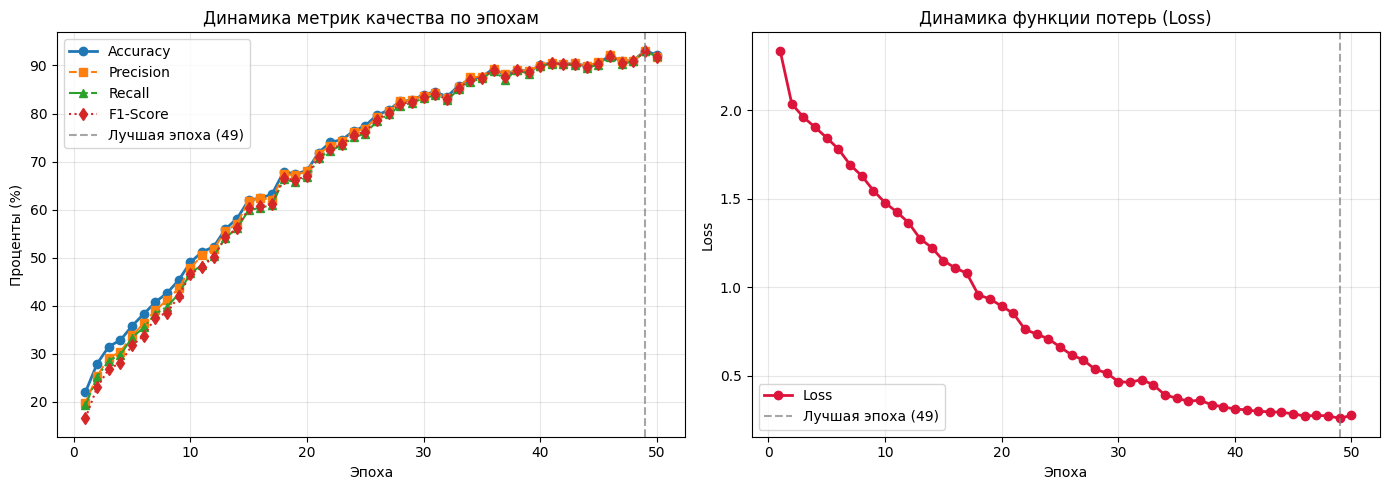

In [71]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), history_acc, label='Accuracy', marker='o', linewidth=2)
plt.plot(range(1, epochs + 1), history_precision, label='Precision', marker='s', linestyle='--')
plt.plot(range(1, epochs + 1), history_recall, label='Recall', marker='^', linestyle='-.')
plt.plot(range(1, epochs + 1), history_f1, label='F1-Score', marker='d', linestyle=':')

plt.axvline(x=best_epoch, color='gray', linestyle='--', alpha=0.7, label=f'Лучшая эпоха ({best_epoch})')

plt.title('Динамика метрик качества по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('Проценты (%)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), history_loss, label='Loss', color='crimson', marker='o', linewidth=2)
plt.axvline(x=best_epoch, color='gray', linestyle='--', alpha=0.7, label=f'Лучшая эпоха ({best_epoch})')

plt.title('Динамика функции потерь (Loss)')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [72]:
import torch
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

best_model.eval()
test_preds = []
test_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        _, predicted = outputs.max(1)

        test_preds.extend(predicted.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(test_labels, test_preds) * 100
test_prec, test_rec, test_f1, _ = precision_recall_fscore_support(
    test_labels, test_preds, average='macro', zero_division=0
)

print("=" * 50)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ (20%):")
print("=" * 50)
print(f"Accuracy:  {test_acc:.2f}%")
print(f"Precision: {test_prec * 100:.2f}%")
print(f"Recall:    {test_rec * 100:.2f}%")
print(f"F1-Score:  {test_f1 * 100:.2f}%")
print("=" * 50)

ИТОГОВЫЕ РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ (20%):
Accuracy:  33.41%
Precision: 32.46%
Recall:    32.65%
F1-Score:  32.29%


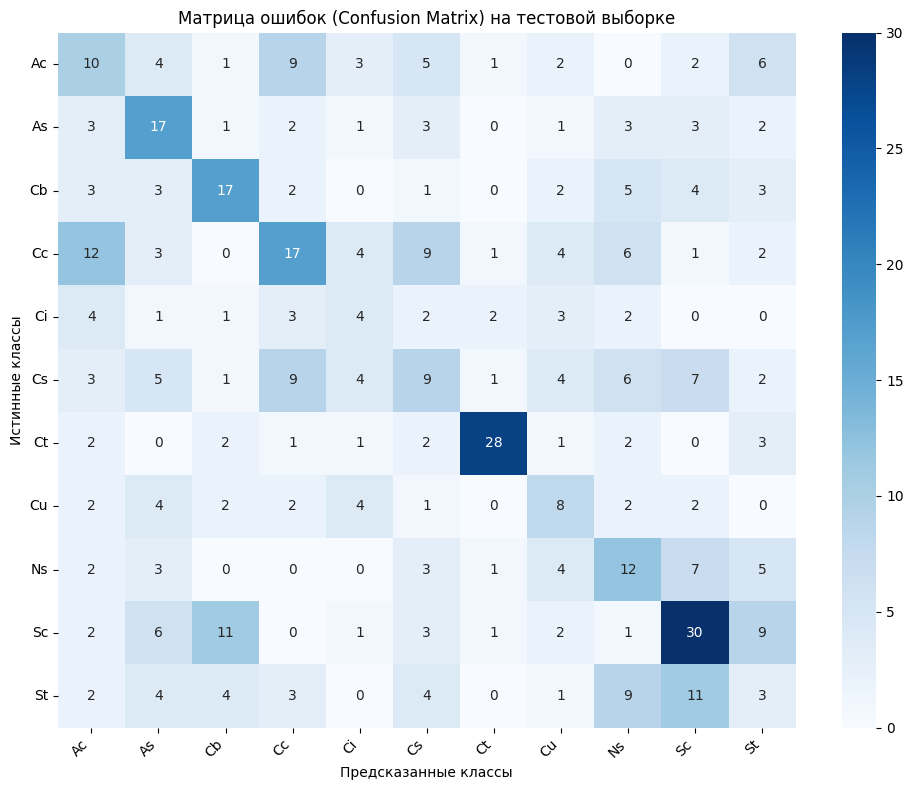

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


cm_test = confusion_matrix(test_labels, test_preds)
class_names = train_full_dataset.classes

plt.figure(figsize=(10, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title('Матрица ошибок (Confusion Matrix) на тестовой выборке')
plt.xlabel('Предсказанные классы')
plt.ylabel('Истинные классы')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Результаты так себе

In [82]:
best_model_mod = ConfigurableCNN(
    num_classes=11,
    num_blocks=best_params['num_blocks'],
    base_filters=best_params['base_filters'],
    kernel_size=best_params['kernel_size'],
    pool_type=best_params['pool_type'],
    use_bn=True,
    use_dropout=True
).to(device)

In [83]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(best_model_mod.parameters(), lr=0.001)

In [84]:
epochs = 15
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

Запуск обучения расширенной модели (32 фильтра, 15 эпох)...

Эпоха 1/15 | Loss: 2.5064 | Acc: 18.02% | Prec: 16.10% | Rec: 16.55% | F1: 15.19% | Время: 16.52с
Эпоха 2/15 | Loss: 2.1246 | Acc: 24.31% | Prec: 22.51% | Rec: 21.96% | F1: 20.53% | Время: 16.46с
Эпоха 3/15 | Loss: 1.9917 | Acc: 28.67% | Prec: 26.65% | Rec: 25.73% | F1: 23.77% | Время: 16.25с
Эпоха 4/15 | Loss: 1.9226 | Acc: 31.36% | Prec: 29.84% | Rec: 29.15% | F1: 27.55% | Время: 16.31с
Эпоха 5/15 | Loss: 1.8284 | Acc: 36.31% | Prec: 35.08% | Rec: 33.92% | F1: 32.47% | Время: 16.17с
Эпоха 6/15 | Loss: 1.7845 | Acc: 38.08% | Prec: 37.41% | Rec: 35.45% | F1: 34.46% | Время: 16.26с
Эпоха 7/15 | Loss: 1.7110 | Acc: 39.05% | Prec: 38.45% | Rec: 36.71% | F1: 36.22% | Время: 16.49с
Эпоха 8/15 | Loss: 1.6774 | Acc: 40.45% | Prec: 40.34% | Rec: 38.36% | F1: 38.04% | Время: 16.67с
Эпоха 9/15 | Loss: 1.6126 | Acc: 43.14% | Prec: 43.01% | Rec: 40.87% | F1: 40.58% | Время: 16.59с
Эпоха 10/15 | Loss: 1.5297 | Acc: 45.13% | Prec: 45.20% |

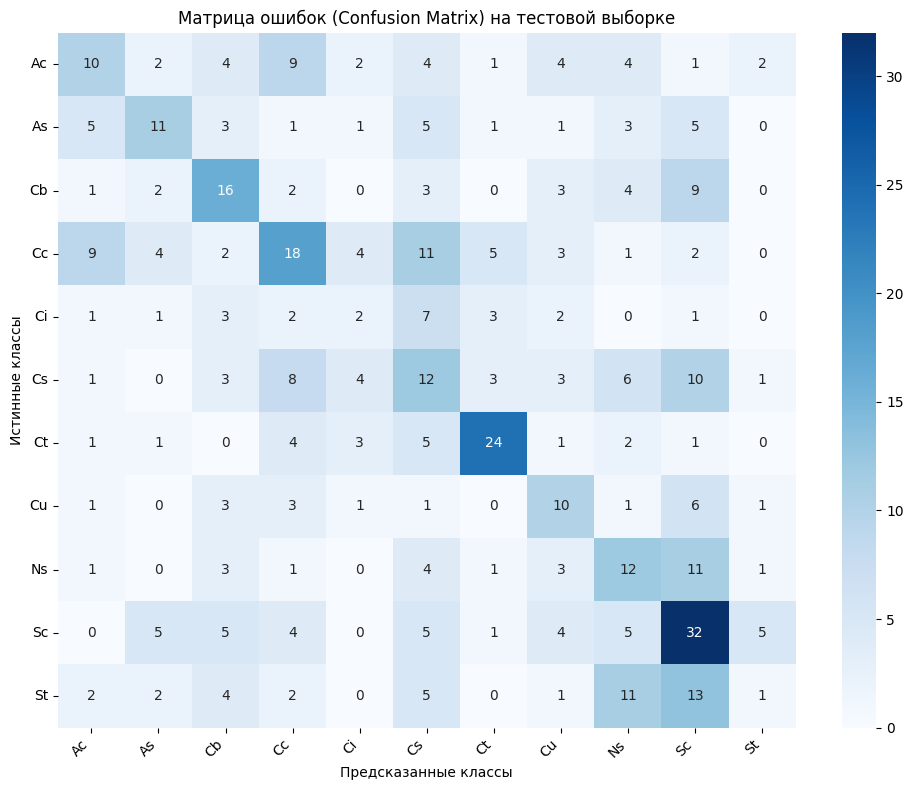

In [88]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 32 фильтра вместо 16
best_model_robust = ConfigurableCNN(
    num_classes=11,
    num_blocks=2,
    base_filters=32,
    kernel_size=3,
    pool_type='max',
    use_bn=False,
    use_dropout=False
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(best_model_robust.parameters(), lr=0.001)

epochs = 15
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

print(f"Запуск обучения расширенной модели (32 фильтра, {epochs} эпох)...\n")
total_start_time = time.time()

for epoch in range(epochs):
    epoch_start_time = time.time()
    best_model_robust.train()
    running_loss = 0.0

    all_preds = []
    all_labels = []

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = best_model_robust(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    scheduler.step()

    epoch_time = time.time() - epoch_start_time
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average='macro', zero_division=0
    )

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = (sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)) * 100

    print(f"Эпоха {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.2f}% | "
          f"Prec: {precision*100:.2f}% | Rec: {recall*100:.2f}% | F1: {f1*100:.2f}% | Время: {epoch_time:.2f}с")

total_time = time.time() - total_start_time
print(f"\nОбучение завершено за {total_time:.2f} сек.")

best_model_robust.eval()
test_preds = []
test_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model_robust(inputs)
        _, predicted = outputs.max(1)

        test_preds.extend(predicted.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(test_labels, test_preds) * 100
test_prec, test_rec, test_f1, _ = precision_recall_fscore_support(
    test_labels, test_preds, average='macro', zero_division=0
)

print("\n" + "="*50)
print("РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ (МОЩНАЯ МОДЕЛЬ):")
print("="*50)
print(f"Accuracy:  {test_acc:.2f}%")
print(f"Precision: {test_prec * 100:.2f}%")
print(f"Recall:    {test_rec * 100:.2f}%")
print(f"F1-Score:  {test_f1 * 100:.2f}%")
print("="*50)

cm_test = confusion_matrix(test_labels, test_preds)
class_names = train_full_dataset.classes

plt.figure(figsize=(10, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Матрица ошибок (Confusion Matrix) на тестовой выборке')
plt.xlabel('Предсказанные классы')
plt.ylabel('Истинные классы')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Обучение MobileNetV3

In [91]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import time
import numpy as np
import matplotlib.pyplot as plt

def get_mobilenet_model(num_classes=11, pretrained=True):
    if pretrained:
        weights = models.MobileNet_V3_Small_Weights.DEFAULT
    else:
        weights = None

    model = models.mobilenet_v3_small(weights=weights)

    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)

    return model.to(device)

### Обучения с нуля

In [92]:
model_scratch = get_mobilenet_model(num_classes=11, pretrained=False)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_scratch.parameters(), lr=0.001)

epochs = 12
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

print("ЭКСПЕРИМЕНТ 1: Обучение MobileNetV3 С НУЛЯ")
total_start_time = time.time()

for epoch in range(epochs):
    epoch_start_time = time.time()
    model_scratch.train()
    running_loss = 0.0

    all_preds = []
    all_labels = []

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_scratch(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    scheduler.step()

    epoch_time = time.time() - epoch_start_time
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = (sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)) * 100

    print(f"Эпоха {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.2f}% | Время: {epoch_time:.2f}с")


ЭКСПЕРИМЕНТ 1: Обучение MobileNetV3 С НУЛЯ
Эпоха 1/12 | Loss: 2.2779 | Acc: 18.72% | Время: 21.21с
Эпоха 2/12 | Loss: 2.1826 | Acc: 22.75% | Время: 17.05с
Эпоха 3/12 | Loss: 2.1217 | Acc: 25.87% | Время: 17.00с
Эпоха 4/12 | Loss: 2.0519 | Acc: 27.97% | Время: 16.81с
Эпоха 5/12 | Loss: 1.9728 | Acc: 32.17% | Время: 17.04с
Эпоха 6/12 | Loss: 1.9448 | Acc: 33.62% | Время: 17.00с
Эпоха 7/12 | Loss: 1.9185 | Acc: 33.62% | Время: 16.96с
Эпоха 8/12 | Loss: 1.8210 | Acc: 38.03% | Время: 17.03с
Эпоха 9/12 | Loss: 1.7970 | Acc: 37.65% | Время: 17.02с
Эпоха 10/12 | Loss: 1.7356 | Acc: 39.91% | Время: 17.03с
Эпоха 11/12 | Loss: 1.7120 | Acc: 40.67% | Время: 17.13с
Эпоха 12/12 | Loss: 1.6764 | Acc: 41.42% | Время: 17.14с


In [102]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

model_scratch.eval()
scratch_preds, scratch_labels = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model_scratch(inputs)
        _, predicted = outputs.max(1)

        scratch_preds.extend(predicted.cpu().numpy())
        scratch_labels.extend(labels.cpu().numpy())

# Считаем все метрики
scratch_acc = accuracy_score(scratch_labels, scratch_preds) * 100
scratch_prec, scratch_rec, scratch_f1, _ = precision_recall_fscore_support(
    scratch_labels, scratch_preds, average='macro', zero_division=0
)

print("\n" + "="*50)
print("РЕЗУЛЬТАТЫ MOBILENETV3 (С НУЛЯ) НА ТЕСТЕ:")
print("="*50)
print(f"Accuracy:  {scratch_acc:.2f}%")
print(f"Precision: {scratch_prec * 100:.2f}%")
print(f"Recall:    {scratch_rec * 100:.2f}%")
print(f"F1-Score:  {scratch_f1 * 100:.2f}%")
print("="*50)


РЕЗУЛЬТАТЫ MOBILENETV3 (С НУЛЯ) НА ТЕСТЕ:
Accuracy:  34.70%
Precision: 32.88%
Recall:    32.45%
F1-Score:  29.33%


### С готовыми весами

In [94]:
model_transfer = get_mobilenet_model(num_classes=11, pretrained=True)

for param in model_transfer.features.parameters():
    param.requires_grad = False

optimizer_tr = optim.Adam(model_transfer.classifier.parameters(), lr=0.001)
scheduler_tr = optim.lr_scheduler.CosineAnnealingLR(optimizer_tr, T_max=epochs)

print("ЭКСПЕРИМЕНТ 2: Transfer Learning (Fine-Tuning)")
total_start_time = time.time()

for epoch in range(epochs):
    epoch_start_time = time.time()
    model_transfer.train()
    running_loss = 0.0

    all_preds = []
    all_labels = []

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer_tr.zero_grad()
        outputs = model_transfer(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_tr.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    scheduler_tr.step()

    epoch_time = time.time() - epoch_start_time
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = (sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)) * 100

    print(f"Эпоха {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.2f}% | Время: {epoch_time:.2f}с")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to C:\Users\arkhi/.cache\torch\hub\checkpoints\mobilenet_v3_small-047dcff4.pth
100.0%


ЭКСПЕРИМЕНТ 2: Transfer Learning (Fine-Tuning)
Эпоха 1/12 | Loss: 2.0633 | Acc: 30.45% | Время: 7.76с
Эпоха 2/12 | Loss: 1.7614 | Acc: 40.77% | Время: 7.49с
Эпоха 3/12 | Loss: 1.7012 | Acc: 41.74% | Время: 10.46с
Эпоха 4/12 | Loss: 1.6171 | Acc: 44.92% | Время: 7.38с
Эпоха 5/12 | Loss: 1.5283 | Acc: 46.75% | Время: 7.21с
Эпоха 6/12 | Loss: 1.4925 | Acc: 48.52% | Время: 7.14с
Эпоха 7/12 | Loss: 1.4639 | Acc: 49.17% | Время: 7.22с
Эпоха 8/12 | Loss: 1.4020 | Acc: 52.02% | Время: 7.12с
Эпоха 9/12 | Loss: 1.3365 | Acc: 53.15% | Время: 7.13с
Эпоха 10/12 | Loss: 1.3281 | Acc: 54.60% | Время: 7.10с
Эпоха 11/12 | Loss: 1.3100 | Acc: 55.08% | Время: 7.10с
Эпоха 12/12 | Loss: 1.3206 | Acc: 55.03% | Время: 7.09с


In [95]:
model_transfer.eval()
tr_preds, tr_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model_transfer(inputs)
        _, predicted = outputs.max(1)
        tr_preds.extend(predicted.cpu().numpy())
        tr_labels.extend(labels.cpu().numpy())

tr_acc = accuracy_score(tr_labels, tr_preds) * 100
tr_prec, tr_rec, tr_f1, _ = precision_recall_fscore_support(tr_labels, tr_preds, average='macro', zero_division=0)

print("\n" + "="*50)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ TRANSFER LEARNING НА ТЕСТЕ:")
print("="*50)
print(f"Accuracy:  {tr_acc:.2f}%")
print(f"Precision: {tr_prec * 100:.2f}%")
print(f"Recall:    {tr_rec * 100:.2f}%")
print(f"F1-Score:  {tr_f1 * 100:.2f}%")
print("="*50)


ИТОГОВЫЕ РЕЗУЛЬТАТЫ TRANSFER LEARNING НА ТЕСТЕ:
Accuracy:  36.64%
Precision: 34.89%
Recall:    35.71%
F1-Score:  34.53%


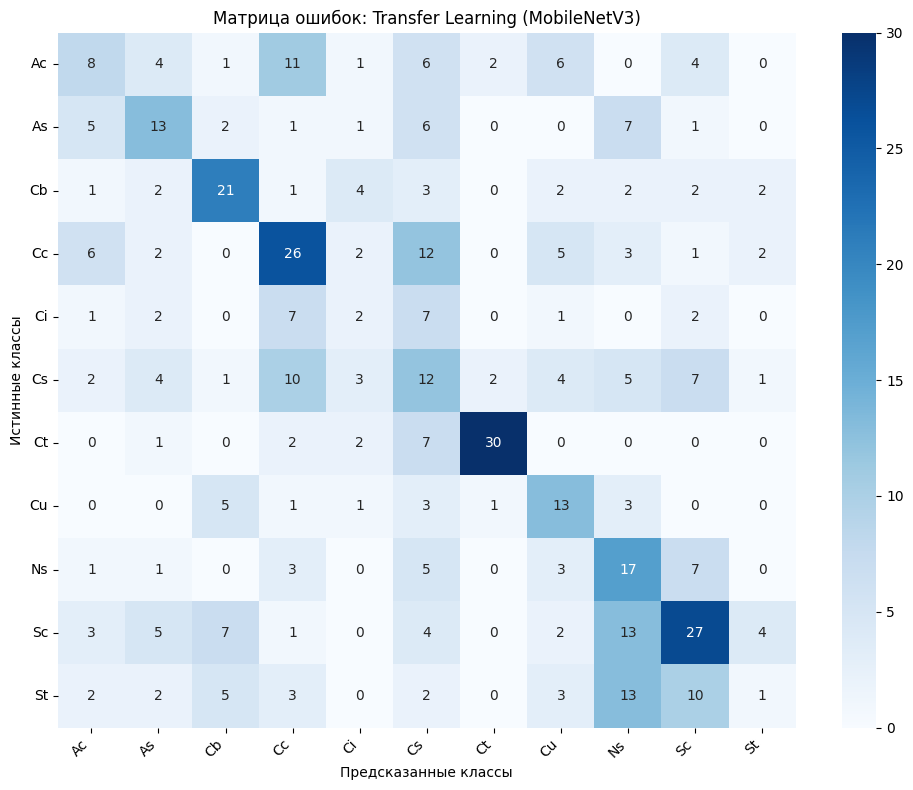

In [96]:
cm_tr = confusion_matrix(tr_labels, tr_preds)
class_names = train_full_dataset.classes

plt.figure(figsize=(10, 8))
sns.heatmap(cm_tr, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Матрица ошибок: Transfer Learning (MobileNetV3)')
plt.xlabel('Предсказанные классы')
plt.ylabel('Истинные классы')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Доп.изучение ResNet18

In [97]:
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import time
import numpy as np
import matplotlib.pyplot as plt

weights = models.ResNet18_Weights.DEFAULT
resnet_model = models.resnet18(weights=weights)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\arkhi/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100.0%


In [98]:
in_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(in_features, 11)
resnet_model = resnet_model.to(device)

In [99]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet_model.fc.parameters(), lr=0.001)

epochs = 12
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

print("ЗАПУСК ОБУЧЕНИЯ RESNET18 (Transfer Learning)\n")
total_start_time = time.time()

for epoch in range(epochs):
    epoch_start_time = time.time()
    resnet_model.train()
    running_loss = 0.0

    all_preds = []
    all_labels = []

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = resnet_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    scheduler.step()

    epoch_time = time.time() - epoch_start_time
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = (sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)) * 100

    print(f"Эпоха {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.2f}% | Время: {epoch_time:.2f}с")

total_time = time.time() - total_start_time
print(f"\nОбучение завершено за {total_time:.2f} сек.")

ЗАПУСК ОБУЧЕНИЯ RESNET18 (Transfer Learning)

Эпоха 1/12 | Loss: 2.2849 | Acc: 21.52% | Время: 15.56с
Эпоха 2/12 | Loss: 1.9383 | Acc: 34.59% | Время: 13.04с
Эпоха 3/12 | Loss: 1.8100 | Acc: 39.70% | Время: 13.14с
Эпоха 4/12 | Loss: 1.7557 | Acc: 39.64% | Время: 13.07с
Эпоха 5/12 | Loss: 1.7139 | Acc: 41.47% | Время: 13.21с
Эпоха 6/12 | Loss: 1.6854 | Acc: 43.36% | Время: 12.99с
Эпоха 7/12 | Loss: 1.6527 | Acc: 44.49% | Время: 13.08с
Эпоха 8/12 | Loss: 1.6260 | Acc: 44.11% | Время: 13.07с
Эпоха 9/12 | Loss: 1.6088 | Acc: 47.12% | Время: 13.00с
Эпоха 10/12 | Loss: 1.5834 | Acc: 45.83% | Время: 13.09с
Эпоха 11/12 | Loss: 1.6017 | Acc: 45.83% | Время: 13.20с
Эпоха 12/12 | Loss: 1.5913 | Acc: 47.44% | Время: 13.87с

Обучение завершено за 160.36 сек.


In [100]:
resnet_model.eval()
test_preds = []
test_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = resnet_model(inputs)
        _, predicted = outputs.max(1)

        test_preds.extend(predicted.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(test_labels, test_preds) * 100
test_prec, test_rec, test_f1, _ = precision_recall_fscore_support(
    test_labels, test_preds, average='macro', zero_division=0
)

print("\n" + "="*50)
print("РЕЗУЛЬТАТЫ RESNET18 НА ТЕСТОВОЙ ВЫБОРКЕ:")
print("="*50)
print(f"Accuracy:  {test_acc:.2f}%")
print(f"Precision: {test_prec * 100:.2f}%")
print(f"Recall:    {test_rec * 100:.2f}%")
print(f"F1-Score:  {test_f1 * 100:.2f}%")
print("="*50)


РЕЗУЛЬТАТЫ RESNET18 НА ТЕСТОВОЙ ВЫБОРКЕ:
Accuracy:  36.42%
Precision: 35.06%
Recall:    36.29%
F1-Score:  34.48%


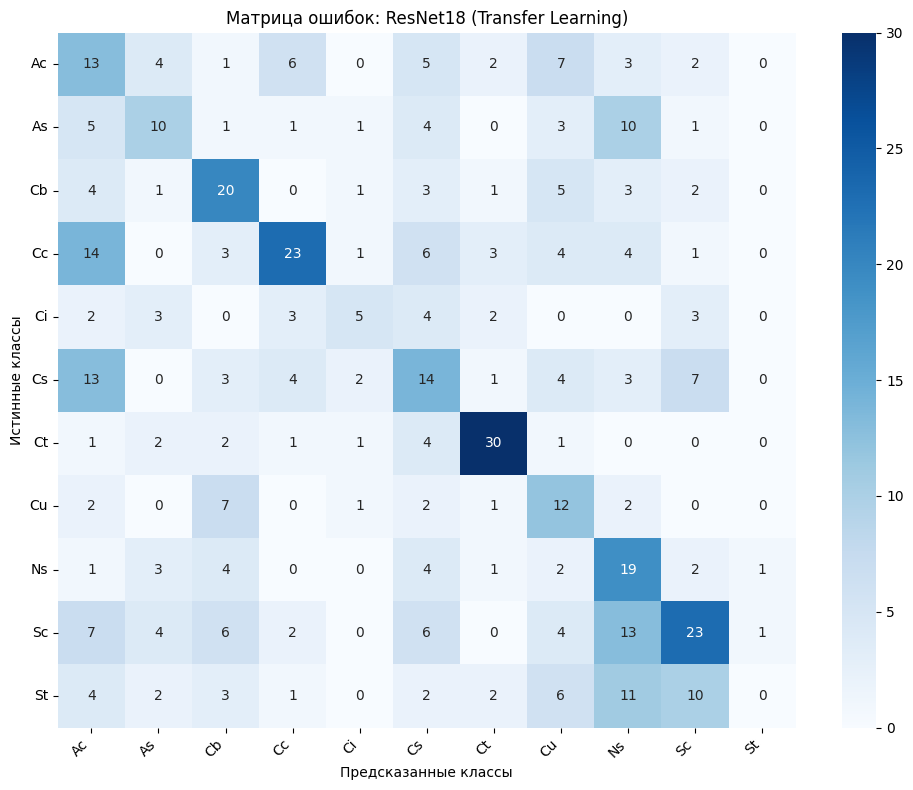

In [101]:
cm_test = confusion_matrix(test_labels, test_preds)
class_names = train_full_dataset.classes

plt.figure(figsize=(10, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Матрица ошибок: ResNet18 (Transfer Learning)')
plt.xlabel('Предсказанные классы')
plt.ylabel('Истинные классы')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Сравнение всех моделей

In [103]:
import numpy as np
import matplotlib.pyplot as plt

results_comparison = {
    'Custom CNN (32 filters)': {
        'Accuracy': 31.90,
        'Precision': 29.88,
        'Recall': 30.41,
        'F1-Score': 29.60
    },
    'MobileNetV3 (Scratch)': {
        'Accuracy': 34.70,
        'Precision': 32.88,
        'Recall': 32.45,
        'F1-Score': 29.33
    },
    'MobileNetV3 (Transfer)': {
        'Accuracy': tr_acc,
        'Precision': tr_prec * 100,
        'Recall': tr_rec * 100,
        'F1-Score': tr_f1 * 100
    },
    'ResNet18 (Transfer)': {
        'Accuracy': test_acc,
        'Precision': test_prec * 100,
        'Recall': test_rec * 100,
        'F1-Score': test_f1 * 100
    }

}

print("=" * 70)
print(f"{'Модель':<28} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 70)
for model_name, metrics in results_comparison.items():
    print(f"{model_name:<28} | {metrics['Accuracy']:<9.2f}% | {metrics['Precision']:<9.2f}% | {metrics['Recall']:<9.2f}% | {metrics['F1-Score']:<9.2f}%")
print("=" * 70)

Модель                       | Accuracy   | Precision  | Recall     | F1-Score  
----------------------------------------------------------------------
Custom CNN (32 filters)      | 31.90    % | 29.88    % | 30.41    % | 29.60    %
MobileNetV3 (Scratch)        | 34.70    % | 32.88    % | 32.45    % | 29.33    %
MobileNetV3 (Transfer)       | 36.64    % | 34.89    % | 35.71    % | 34.53    %
ResNet18 (Transfer)          | 36.42    % | 35.06    % | 36.29    % | 34.48    %


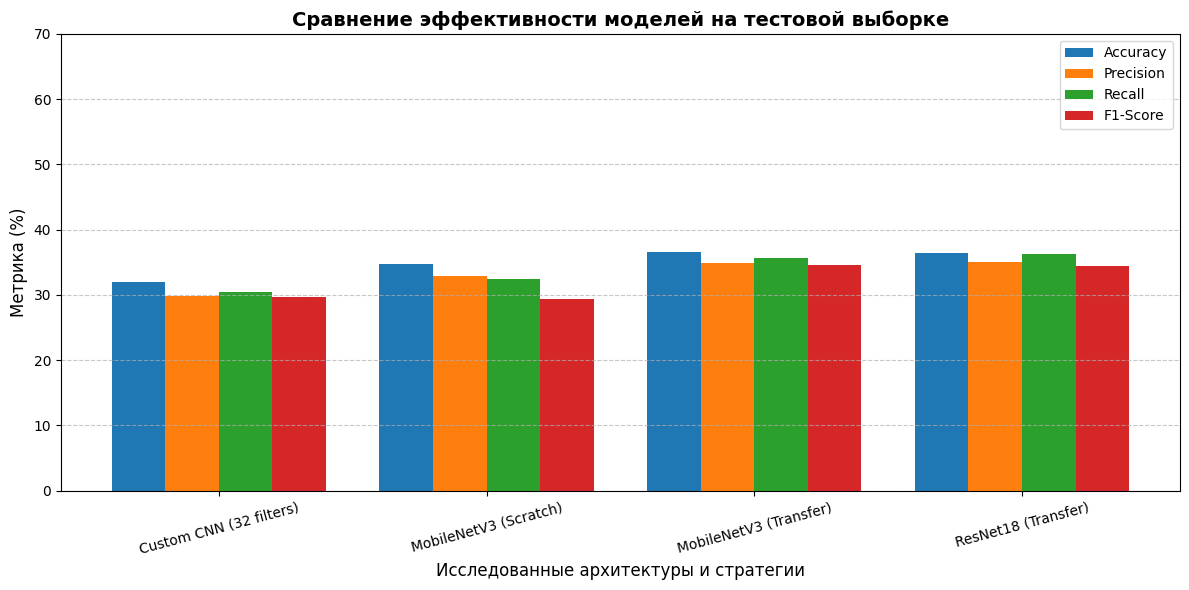

In [104]:
models_list = list(results_comparison.keys())
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

x = np.arange(len(models_list))
width = 0.2

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics_names):
    values = [results_comparison[m][metric] for m in models_list]
    offset = (i - 1.5) * width
    plt.bar(x + offset, values, width, label=metric)

plt.xlabel('Исследованные архитектуры и стратегии', fontsize=12)
plt.ylabel('Метрика (%)', fontsize=12)
plt.title('Сравнение эффективности моделей на тестовой выборке', fontsize=14, fontweight='bold')
plt.xticks(x, models_list, rotation=15)
plt.ylim(0, 70)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Вывод: датасет плохой. Разные модели уперлись в один и тот же потолок

## Изучение влияния количетсва замороженных слоев на ResNet50

In [106]:
from torchvision import models, transforms
import numpy as np

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT).to(device)

for param in model.parameters():
    param.requires_grad = False

model.eval()

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def deprocess(tensor):
    denorm = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )
    img = denorm(tensor.clone().detach())
    img = torch.clamp(img, 0, 1)
    return img.permute(1, 2, 0).cpu().numpy()

activation = {}
def get_activation(name):
    def hook(model, input, output):
        activation[name] = output
    return hook

layer_to_visualize = model.layer2
h = layer_to_visualize.register_forward_hook(get_activation('layer2'))

def deep_dream_step(image, model, step_size=0.05):
    if image.grad is not None:
        image.grad.data.zero_()

    _ = model(image)

    act = activation['layer2']
    loss = act.norm()
    loss.backward()

    with torch.no_grad():
        grad = image.grad.data
        grad = grad / (torch.std(grad) + 1e-8)
        image.data += step_size * grad
        image.data = torch.clamp(image.data, -2.2, 2.2)

    return loss.item()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\arkhi/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth
100.0%


In [110]:
import torch
import torch.nn as nn

def get_resnet50_layers_grouped():
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, 11)

    layer_groups = [
        list(model.conv1.parameters()) + list(model.bn1.parameters()) + list(model.layer1.parameters()),
        list(model.layer2.parameters()),
        list(model.layer3.parameters()),
        list(model.layer4.parameters()) + list(model.fc.parameters())
    ]

    return model, layer_groups

def set_frozen_percentage(model, layer_groups, freeze_pct):
    for group in layer_groups:
        for param in group:
            param.requires_grad = False

    total_groups = len(layer_groups)
    num_groups_to_freeze = int(total_groups * (freeze_pct / 100.0))

    for i in range(total_groups):
        if i >= num_groups_to_freeze:
            for param in layer_groups[i]:
                param.requires_grad = True

    for param in model.fc.parameters():
        param.requires_grad = True

freeze_steps = [100, 75, 50, 25, 0]

for pct in freeze_steps:
    print(f"\n--- Эксперимент: Заморожено {pct}% слоев баты ---")

    model, layer_groups = get_resnet50_layers_grouped()
    set_frozen_percentage(model, layer_groups, freeze_pct=pct)

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Обучаемых параметров: {trainable_params:,} из {total_params:,} ({trainable_params/total_params*100:.1f}%)")


--- Эксперимент: Заморожено 100% слоев баты ---
Обучаемых параметров: 22,539 из 23,530,571 (0.1%)

--- Эксперимент: Заморожено 75% слоев баты ---
Обучаемых параметров: 14,987,275 из 23,530,571 (63.7%)

--- Эксперимент: Заморожено 50% слоев баты ---
Обучаемых параметров: 22,085,643 из 23,530,571 (93.9%)

--- Эксперимент: Заморожено 25% слоев баты ---
Обучаемых параметров: 23,305,227 из 23,530,571 (99.0%)

--- Эксперимент: Заморожено 0% слоев баты ---
Обучаемых параметров: 23,530,571 из 23,530,571 (100.0%)


In [112]:
results = {}

freeze_steps = [100, 75, 50, 25, 0]

for pct in freeze_steps:
    print(f"\n=== Запуск обучения: Заморожено {pct}% ===")

    model, layer_groups = get_resnet50_layers_grouped()
    set_frozen_percentage(model, layer_groups, freeze_pct=pct)
    model.to(device)

    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)
    criterion = nn.CrossEntropyLoss()

    epochs = 3
    for epoch in range(epochs):
        model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total
    results[pct] = val_acc
    print(f"Результат (Заморозка {pct}%): Accuracy = {val_acc:.2f}%")

print("\n Итоги эксперимента по заморозке:", results)


=== Запуск обучения: Заморожено 100% ===
Результат (Заморозка 100%): Accuracy = 26.51%

=== Запуск обучения: Заморожено 75% ===
Результат (Заморозка 75%): Accuracy = 43.97%

=== Запуск обучения: Заморожено 50% ===
Результат (Заморозка 50%): Accuracy = 46.55%

=== Запуск обучения: Заморожено 25% ===
Результат (Заморозка 25%): Accuracy = 46.77%

=== Запуск обучения: Заморожено 0% ===
Результат (Заморозка 0%): Accuracy = 45.47%

 Итоги эксперимента по заморозке: {100: 26.50862068965517, 75: 43.96551724137931, 50: 46.55172413793103, 25: 46.76724137931034, 0: 45.474137931034484}


100% заморозки (Accuracy = 26.51%): Обучался исключительно выходной классификатор. Низкий показатель объясняется тем, что предобученные признаки «из коробки» недостаточно адаптированы под специфику целевого датасета.

75% заморозки (Accuracy = 43.97%): Разморозка глубокого блока позволила существенно поднять точность, так как модель начала настраивать высокоуровневые семантические признаки под новые классы.

50% и 25% заморозки (Accuracy = 46.55% – 46.77%): Постепенная разморозка средних слоев сети показала наилучшие результаты.

0% заморозки / Полный Fine-Tuning (Accuracy = 45.47%): Обучение всех 23 миллионов параметров сети показало незначительное снижение точности за фиксированное число эпох, что связано с необходимостью более долгой сходимости и повышенным риском переобучения на старте.

## DeepDream

In [119]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

model.eval()

for param in model.parameters():
    param.requires_grad = False

mean = torch.tensor([0.485, 0.456, 0.406]).to(device)
std = torch.tensor([0.229, 0.224, 0.225]).to(device)

def preprocess_image(image_path, size=(224, 224)):
    image = Image.open(image_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize(size),
        transforms.ToTensor(),
    ])
    tensor = transform(image).unsqueeze(0).to(device)
    tensor = (tensor - mean[:, None, None]) / std[:, None, None]
    tensor.requires_grad_(True)
    return tensor

def deprocess_image(tensor):
    tensor = tensor.detach().squeeze(0)
    tensor = tensor * std[:, None, None] + mean[:, None, None]
    tensor = torch.clamp(tensor, 0, 1)
    img = tensor.permute(1, 2, 0).cpu().numpy()
    return (img * 255).astype(np.uint8)

activation = {}
def get_activation(name):
    def hook(model, input, output):
        activation[name] = output
    return hook

target_layer = model.layer2
hook_handle = target_layer.register_forward_hook(get_activation('target_layer'))

def run_deep_dream(image_tensor, steps=100, step_size=0.05):
    for step in range(steps):
        if image_tensor.grad is not None:
            image_tensor.grad.data.zero_()

        _ = model(image_tensor)
        act = activation['target_layer']
        loss = act.norm()
        loss.backward()

        with torch.no_grad():
            grad = image_tensor.grad.data
            grad = grad / (torch.std(grad) + 1e-8)
            image_tensor.data += step_size * grad

            for c in range(3):
                image_tensor.data[0, c] = torch.clamp(
                    image_tensor.data[0, c],
                    -mean[c] / std[c],
                    (1.0 - mean[c]) / std[c]
                )

        if step % 20 == 0:
            print(f"Шаг {step}, Loss: {loss.item():.4f}")

    return image_tensor

def run_deep_dream_with_history(image_tensor, steps=150, step_size=0.03, save_every=30):
    history = []
    history.append((0, deprocess_image(image_tensor.clone())))

    for step in range(1, steps + 1):
        if image_tensor.grad is not None:
            image_tensor.grad.data.zero_()

        _ = model(image_tensor)
        act = activation['target_layer']
        loss = act.norm()
        loss.backward()

        with torch.no_grad():
            grad = image_tensor.grad.data
            grad = grad / (torch.std(grad) + 1e-8)
            image_tensor.data += step_size * grad

            for c in range(3):
                image_tensor.data[0, c] = torch.clamp(
                    image_tensor.data[0, c],
                    -mean[c] / std[c],
                    (1.0 - mean[c]) / std[c]
                )

        if step % save_every == 0 or step == steps:
            print(f"Шаг {step}, Loss: {loss.item():.4f}")
            history.append((step, deprocess_image(image_tensor.clone())))

    return image_tensor, history

Шаг 30, Loss: 2441.0271
Шаг 60, Loss: 2968.1084
Шаг 90, Loss: 3330.3267
Шаг 120, Loss: 3626.6316
Шаг 150, Loss: 3864.7515


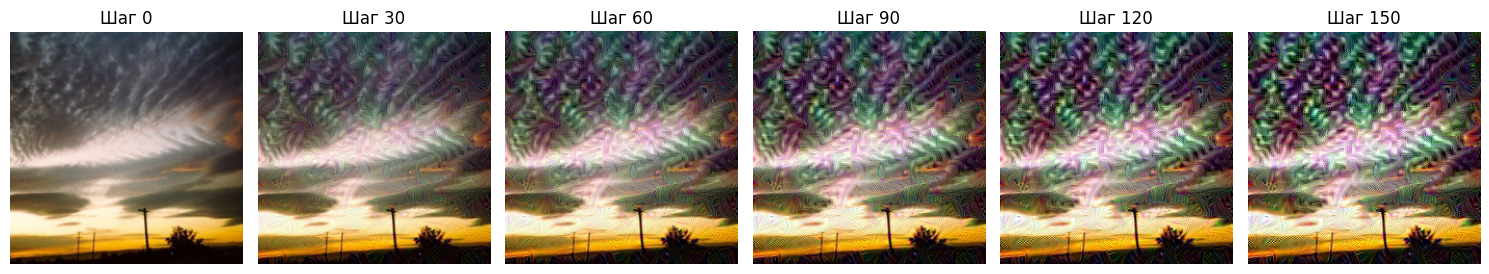

In [120]:
img_tensor = preprocess_image("data/train/Ac/Ac-N001.jpg", size=(224, 224))

optimized_tensor, history = run_deep_dream_with_history(img_tensor, steps=150, step_size=0.03, save_every=30)

hook_handle.remove()

num_images = len(history)
plt.figure(figsize=(15, 3))

for i, (step, img_np) in enumerate(history):
    plt.subplot(1, num_images, i + 1)
    plt.imshow(img_np)
    plt.axis('off')
    plt.title(f"Шаг {step}")

plt.tight_layout()
plt.show()

С помощью алгоритма градиентного восхождения была выполнена максимизация активаций промежуточного слоя. В процессе значения функции потерь планомерно увеличивались, что подтверждает успешное усиление отклика нейросети.

## Анализ ошибок

In [131]:
import torch
import matplotlib.pyplot as plt
import os

model.eval()
error_cases = []
subset_dataset = test_loader.dataset
original_dataset = subset_dataset.dataset

with torch.no_grad():
    batch_size = test_loader.batch_size
    for batch_idx, (images, labels) in enumerate(test_loader):
        images_dev, labels_dev = images.to(device), labels.to(device)
        outputs = model(images_dev)
        _, predicted = torch.max(outputs, 1)

        for i in range(len(labels)):
            if predicted[i] != labels_dev[i]:
                local_idx = batch_idx * batch_size + i
                if local_idx < len(subset_dataset):
                    original_idx = subset_dataset.indices[local_idx]
                    if hasattr(original_dataset, 'imgs'):
                        img_path = original_dataset.imgs[original_idx][0]
                        filename = os.path.basename(img_path)
                    elif hasattr(original_dataset, 'samples'):
                        img_path = original_dataset.samples[original_idx][0]
                        filename = os.path.basename(img_path)
                    else:
                        filename = f"sample_{original_idx}"

                    error_cases.append({
                        'image_tensor': images[i],
                        'true_label': labels[i].item(),
                        'pred_label': predicted[i].item(),
                        'filename': filename
                    })
                    if len(error_cases) >= 5:
                        break
        if len(error_cases) >= 5:
            break

print(f"Найдено ошибок для анализа: {len(error_cases)}")

Найдено ошибок для анализа: 5


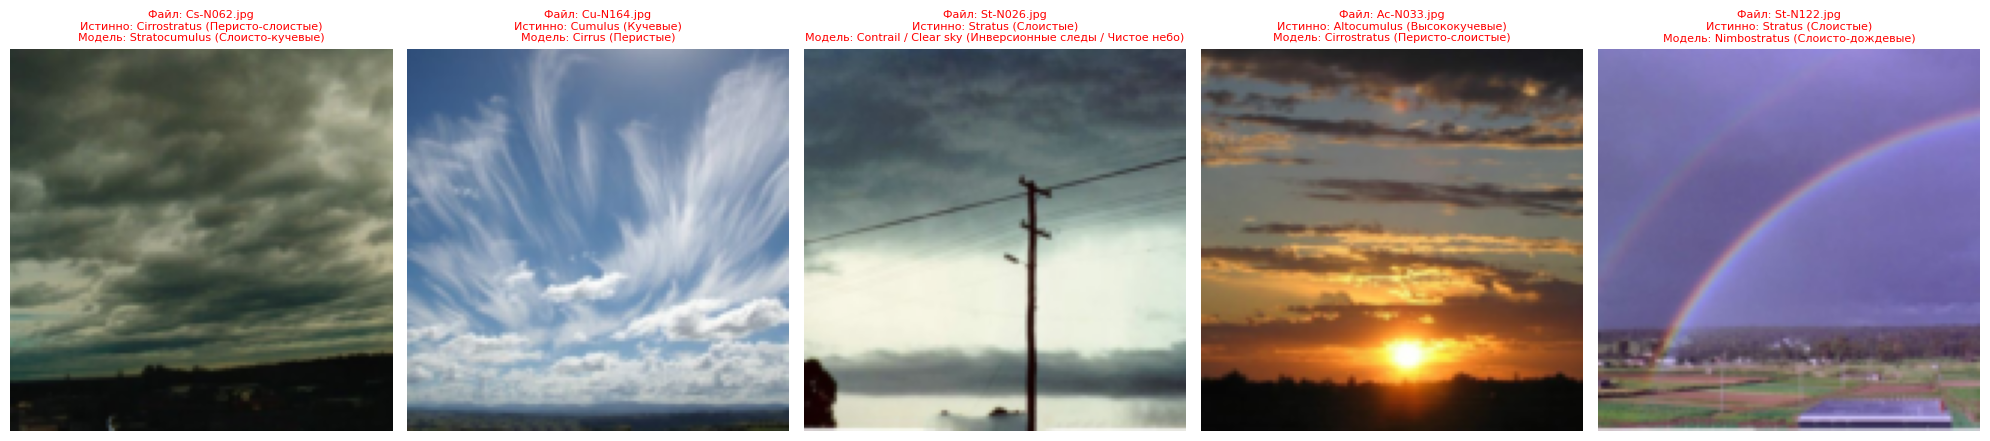

In [132]:
mean_t = torch.tensor([0.485, 0.456, 0.406])
std_t = torch.tensor([0.229, 0.224, 0.225])

plt.figure(figsize=(20, 5))

for idx, case in enumerate(error_cases):
    plt.subplot(1, len(error_cases), idx + 1)

    img = case['image_tensor'].clone().cpu()
    for c in range(3):
        img[c] = img[c] * std_t[c] + mean_t[c]
    img = torch.clamp(img, 0, 1)

    img_np = img.permute(1, 2, 0).numpy()

    plt.imshow(img_np)
    plt.axis('off')

    true_code = class_names[case['true_label']]
    pred_code = class_names[case['pred_label']]

    true_name = cloud_descriptions.get(true_code, true_code)
    pred_name = cloud_descriptions.get(pred_code, pred_code)

    title_text = f"Файл: {case['filename']}\nИстинно: {true_name}\nМодель: {pred_name}"
    plt.title(title_text, color='red', fontsize=8)

plt.tight_layout()
plt.show()

In [135]:
import torch
from torchvision import transforms
import torch.nn.functional as F

model.eval()

mean = torch.tensor([0.485, 0.456, 0.406]).to(device)
std = torch.tensor([0.229, 0.224, 0.225]).to(device)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def predict_image(image_path):
    image = Image.open(image_path).convert('RGB')
    tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(tensor)
        probs = F.softmax(output, dim=1)
        conf, pred = torch.max(probs, 1)

    class_code = class_names[pred.item()]
    class_desc = cloud_descriptions.get(class_code, class_code)
    return class_desc, conf.item()

images_to_test = {
    "Оригинал (ошибка)": "data/train/St/St-N026.jpg",
    "Mod 1 (без стоба, с проводами)": "data/St-N026_mod1.jpg",
    "Mod 2 (полностью очищено)": "data/St-N026_mod2.jpg"
}

for name, path in images_to_test.items():
    try:
        pred_name, confidence = predict_image(path)
        print(f"[{name}] -> Предсказание модели: {pred_name} (Уверенность: {confidence * 100:.2f}%)")
    except Exception as e:
        print(f"[{name}] Ошибка загрузки (проверьте путь к файлу): {e}")

[Оригинал (ошибка)] -> Предсказание модели: Cirrostratus (Перисто-слоистые) (Уверенность: 18.45%)
[Mod 1 (без стоба, с проводами)] -> Предсказание модели: Stratus (Слоистые) (Уверенность: 17.03%)
[Mod 2 (полностью очищено)] -> Предсказание модели: Nimbostratus (Слоисто-дождевые) (Уверенность: 39.89%)


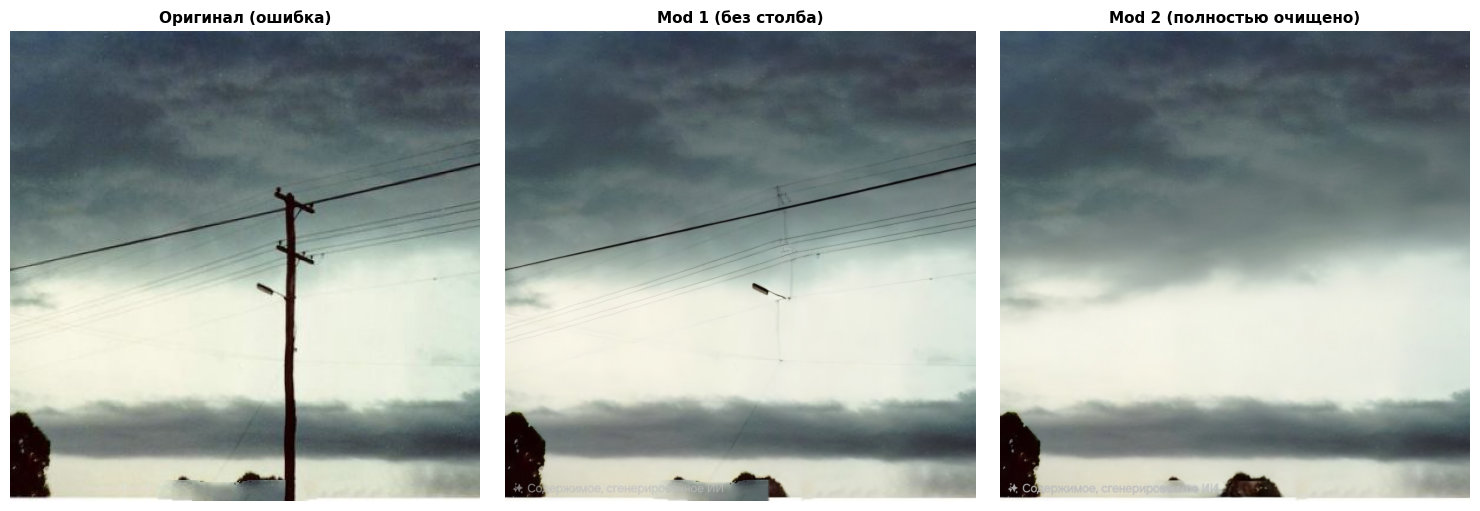

In [137]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(15, 5))

for idx, (title, path) in enumerate(images_to_test.items()):
    plt.subplot(1, len(images_to_test), idx + 1)
    try:
        img = Image.open(path).convert('RGB')
        plt.imshow(img)
        plt.title(title, fontsize=11, fontweight='bold')
    except FileNotFoundError:
        plt.text(0.5, 0.5, f"Файл не найден:\n{path}", horizontalalignment='center', verticalalignment='center', color='red')

    plt.axis('off')

plt.tight_layout()
plt.show()